In [29]:
import pandas as pd
import numpy as np

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
df = pd.read_csv("hw_4_data.csv")

In [32]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Data Preparation


In [33]:
df.isna().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [34]:
cat_cols = df.select_dtypes(include = ['object','category']).columns
num_cols = df.select_dtypes(include = ['number']).columns

In [35]:
df[cat_cols] = df[cat_cols].fillna('NA')
df[num_cols] = df[num_cols].fillna('0.0')

In [36]:
df.isna().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


ROC AUC feature importance


In [37]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

In [38]:
from sklearn.metrics import roc_auc_score

num = ['lead_score','number_of_courses_viewed','interaction_count','annual_income']
y_train = df_train['converted']

for i in num:
    auc = roc_auc_score(y_train, df_train[i])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[i])
    print(f"{i}: {auc:.4f}")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


Train the model


In [39]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

y_train = df_train['converted'].values
y_val = df_val["converted"].values

features = [c for c in df_train.columns if c != 'converted']

dv = DictVectorizer(sparse=False)
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver = 'liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:,1]
val_auc = roc_auc_score(y_val, y_pred)

print(f"Validation AUC: {val_auc:.4f}")

Validation AUC: 0.7313


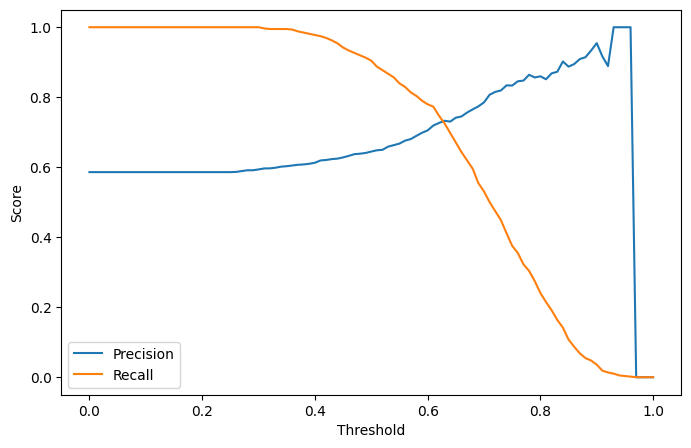

Intersection at threshold: 0.63 (diff: 0.0075)


In [41]:
import matplotlib.pyplot as plt

thresholds = np.linspace(0.0, 1.0, 101)
scores = []

for t in thresholds:
    actual_pos = (y_val == 1)
    actual_neg = (y_val == 0)

    pred_pos = (y_pred >= t)
    pred_neg = (y_pred < t)

    tp = (pred_pos & actual_pos).sum()
    fp = (pred_pos & actual_neg).sum()
    fn = (pred_neg & actual_pos).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((round(t, 2), p, r, abs(p - r)))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall', 'diff'])

# Filter out points where both metrics are zero
valid_scores = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)]

# Plot curves
plt.figure(figsize=(8, 5))
plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

# Find the threshold with the minimum absolute difference
best_row = valid_scores.loc[valid_scores['diff'].idxmin()]
print(f"Intersection at threshold: {best_row['threshold']} (diff: {best_row['diff']:.4f})")

In [40]:
from sklearn.metrics import f1_score
thresholds = np.linspace(0.0, 1.0, 101)
f1_scores = []

for t in thresholds:
    pred = (y_pred >= t).astype(int)
    f1 = f1_score(y_val, pred, zero_division=0)
    f1_scores.append((round(t, 2), f1))

scores_df = pd.DataFrame(f1_scores, columns=['threshold', 'f1'])

# Find the threshold with the maximal F1 score
max_row = scores_df.loc[scores_df['f1'].idxmax()]
print(f"Maximal F1: {max_row['f1']:.4f} at threshold: {max_row['threshold']}")

Maximal F1: 0.7573 at threshold: 0.41


In [42]:
from sklearn.model_selection import KFold

# Ensure index is reset for clean positional slicing
df_full_train = df_full_train.reset_index(drop=True)

# 1. Initialize KFold
kf = KFold(n_splits=5, shuffle=True, random_state=1)

features = [c for c in df_full_train.columns if c != 'converted']
scores = []

# 2. Iterate over the folds of df_full_train
for train_idx, val_idx in kf.split(df_full_train):
    df_train_k = df_full_train.iloc[train_idx]
    df_val_k = df_full_train.iloc[val_idx]

    y_train_k = df_train_k['converted'].values
    y_val_k = df_val_k['converted'].values

    # DictVectorizer encoding
    dv = DictVectorizer(sparse=False)
    train_dicts = df_train_k[features].to_dict(orient='records')
    val_dicts = df_val_k[features].to_dict(orient='records')

    X_train_k = dv.fit_transform(train_dicts)
    X_val_k = dv.transform(val_dicts)

    # Train model
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train_k, y_train_k)

    # Evaluate on validation fold
    y_pred_k = model.predict_proba(X_val_k)[:, 1]
    scores.append(roc_auc_score(y_val_k, y_pred_k))

print("Fold AUCs:", np.round(scores, 4))
print(f"Mean AUC: {np.mean(scores):.4f}")
print(f"Std Dev:  {np.std(scores):.3f}")

Fold AUCs: [0.7312 0.7291 0.7373 0.7411 0.7206]
Mean AUC: 0.7318
Std Dev:  0.007


In [43]:
c_values = [0.000001, 0.001, 1]
kf = KFold(n_splits=5, shuffle=True, random_state=1)
features = [c for c in df_full_train.columns if c != 'converted']

for C in c_values:
    scores = []
    for train_idx, val_idx in kf.split(df_full_train):
        df_train_k = df_full_train.iloc[train_idx]
        df_val_k = df_full_train.iloc[val_idx]

        y_train_k = df_train_k['converted'].values
        y_val_k = df_val_k['converted'].values

        dv = DictVectorizer(sparse=False)
        train_dicts = df_train_k[features].to_dict(orient='records')
        val_dicts = df_val_k[features].to_dict(orient='records')

        X_train_k = dv.fit_transform(train_dicts)
        X_val_k = dv.transform(val_dicts)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_k, y_train_k)

        y_pred_k = model.predict_proba(X_val_k)[:, 1]
        scores.append(roc_auc_score(y_val_k, y_pred_k))

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    print(f"C={C:>8} | Mean AUC: {mean_auc:.3f} | Std: {std_auc:.3f}")

C=   1e-06 | Mean AUC: 0.617 | Std: 0.019
C=   0.001 | Mean AUC: 0.750 | Std: 0.010
C=       1 | Mean AUC: 0.732 | Std: 0.007
